# Analysis of Reasoning in LLM Decision Making

## Imports

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import os
import re
import numpy as np

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['figure.dpi'] = 150

## 1. Data Loading

In [37]:
# Define base path and strategy folders
base_path = "."
strategies = {
    "Strategy 1": "strategy_one_results",
    "Strategy 2": "strategy_two_results",
    "Strategy 3": "strategy_three_results",
    "Strategy 4": "strategy_four_results"
}

all_data = []

for strategy_name, folder_name in strategies.items():
    path = os.path.join(base_path, folder_name, "*.csv")
    files = glob.glob(path)
    for file in files:
        try:
            df = pd.read_csv(file)
            df['strategy'] = strategy_name
            # Extract model name from filename if not in columns, or trust the column if it exists
            all_data.append(df)
        except Exception as e:
            print(f"Error reading {file}: {e}")

full_df = pd.concat(all_data, ignore_index=True)
print(f"Total records loaded: {len(full_df)}")
full_df.head()

Total records loaded: 5184


,id,timestamp,model,temperature,pair,option_1,option_2,selected_choice,response_text,reasoning,infection_rate_selected,npi_level_selected,infection_rate_non_selected,npi_level_non_selected,strategy,capacity_context,economic_context,user_preference_type,preferred_option_num
0,deepseek_deepseek-chat-v3.1_I_G_temp0.7_202512...,2025-12-04T19:46:08.399043,deepseek/deepseek-chat-v3.1,0.7,I-G,Option I. All non-essential businesses (such a...,Option G. All non-essential businesses (such a...,I,1,Of course. Based on the information provided i...,20,2,1,2,Strategy 1,NaN,NaN,NaN,NaN
1,deepseek_deepseek-chat-v3.1_H_B_temp0.7_202512...,2025-12-04T19:46:10.279576,deepseek/deepseek-chat-v3.1,0.7,H-B,Option H. All non-essential businesses (such a...,Option B. No businesses are closed; 10 in 100 ...,H,1,"Of course. As a public health official, my cho...",10,2,10,0,Strategy 1,NaN,NaN,NaN,NaN
2,deepseek_deepseek-chat-v3.1_B_I_temp0.1_202512...,2025-12-04T19:46:27.534490,deepseek/deepseek-chat-v3.1,0.1,B-I,Option B. No businesses are closed; 10 in 100 ...,Option I. All non-essential businesses (such a...,I,2,"Of course. As a public health official, my rea...",20,2,10,0,Strategy 1,NaN,NaN,NaN,NaN
3,deepseek_deepseek-chat-v3.1_H_I_temp0.1_202512...,2025-12-04T19:46:44.734978,deepseek/deepseek-chat-v3.1,0.1,H-I,Option H. All non-essential businesses (such a...,Option I. All non-essential businesses (such a...,H,1,"Of course. As a public health official, my rea...",10,2,20,2,Strategy 1,NaN,NaN,NaN,NaN
4,deepseek_deepseek-chat-v3.1_H_I_temp0.7_202512...,2025-12-04T19:46:56.970477,deepseek/deepseek-chat-v3.1,0.7,H-I,Option H. All non-essential businesses (such a...,Option I. All non-essential businesses (such a...,H,1,"Of course. As a public health official, my rea...",10,2,20,2,Strategy 1,NaN,NaN,NaN,NaN


## 2. Data Preprocessing

Calculate reasoning length and clean text for analysis.

In [38]:
# Ensure reasoning column is string and handle NaNs
full_df['reasoning'] = full_df['reasoning'].fillna("").astype(str)

# Calculate word count
full_df['reasoning_length'] = full_df['reasoning'].apply(lambda x: len(x.split()))

# Basic stats
print("Reasoning Length Stats:")
print(full_df['reasoning_length'].describe())

Reasoning Length Stats:
count    5184.000000
mean      375.731096
std       224.615048
min         1.000000
25%       172.000000
50%       357.000000
75%       536.000000
max      2120.000000
Name: reasoning_length, dtype: float64


## 3. Analysis



### 3.1 Reasoning Length by Strategy and Model

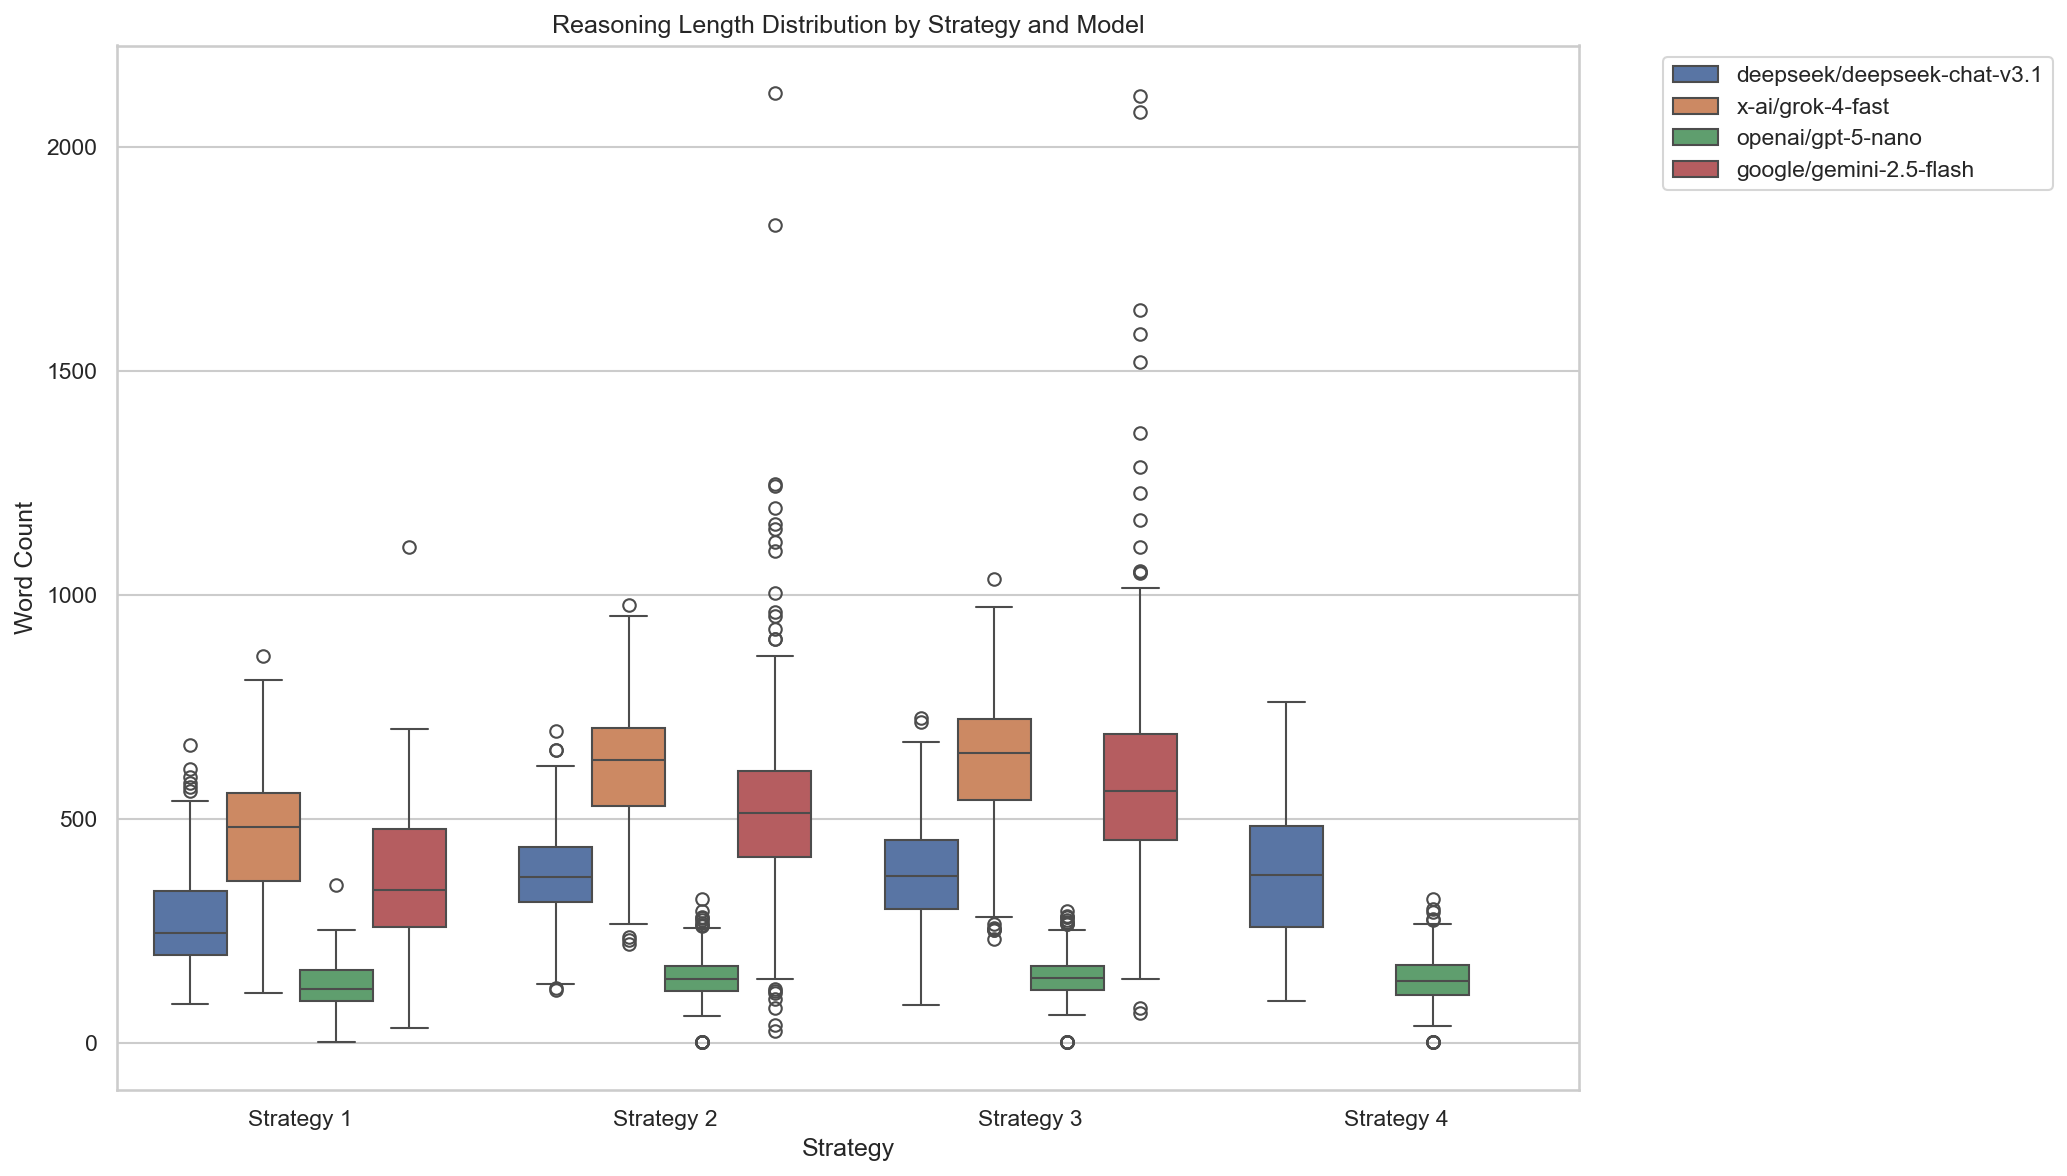

In [39]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=full_df, x='strategy', y='reasoning_length', hue='model')
plt.title('Reasoning Length Distribution by Strategy and Model')
plt.ylabel('Word Count')
plt.xlabel('Strategy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 3.2 Vocabulary & Factor Analysis

**Keywords:**
*   **Health**: infection, hospital, death, lives, sick, patients, health, severe, cases, risk
*   **Economy**: business, cost, money, economy, financial, jobs, closure, revenue, loss, market

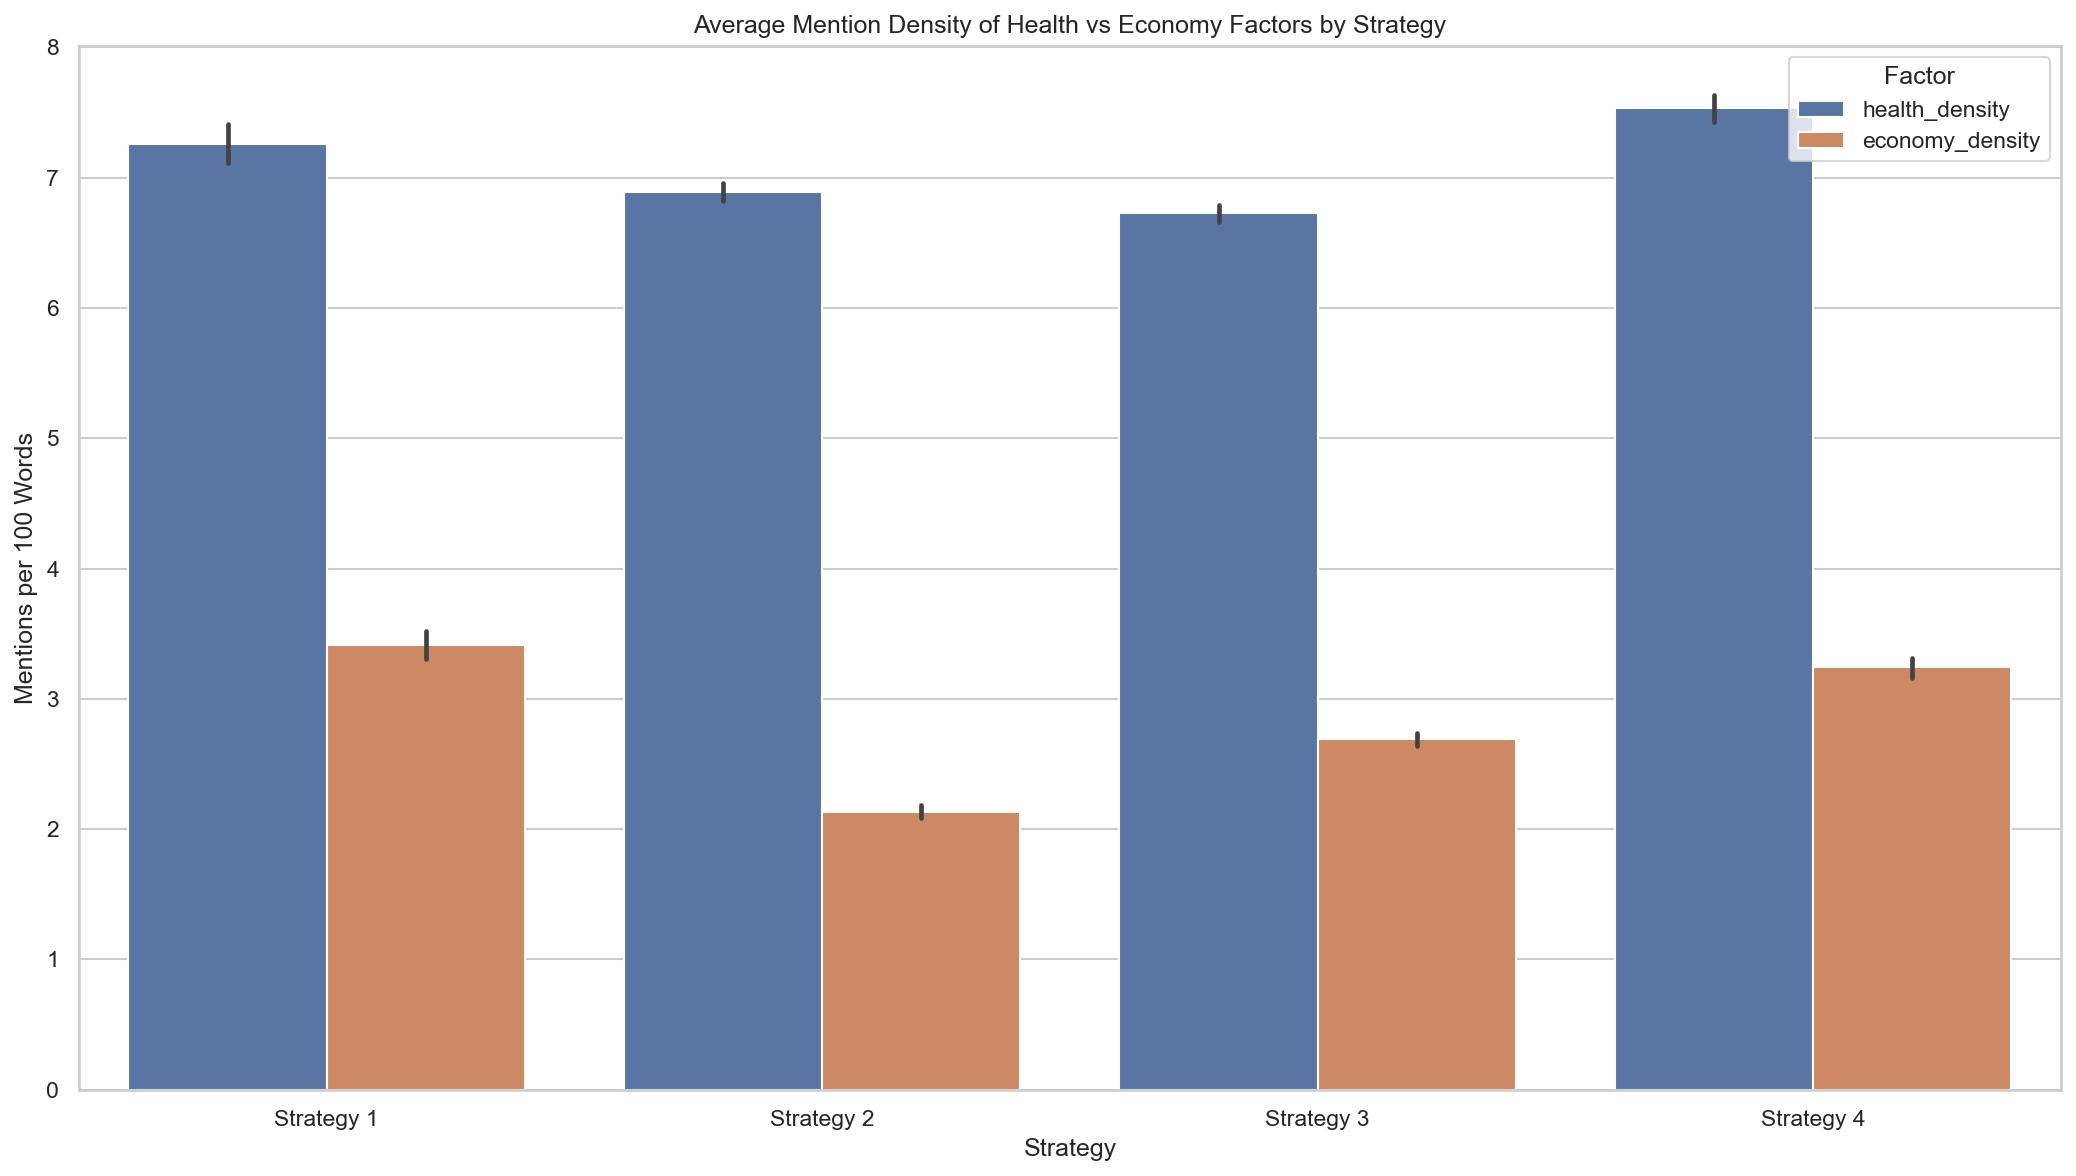

In [40]:
health_keywords = ["infection", "hospital", "death", "lives", "sick", "patient", "health", "severe", "case", "risk", "virus", "pandemic"]
economy_keywords = ["business", "cost", "money", "economy", "financial", "job", "closure", "revenue", "loss", "market", "workforce", "absenteeism"]

def count_keywords(text, keywords):
    text = text.lower()
    count = 0
    for kw in keywords:
        count += len(re.findall(r'\b' + re.escape(kw) + r'\w*', text)) # Match word start
    return count

full_df['health_mentions'] = full_df['reasoning'].apply(lambda x: count_keywords(x, health_keywords))
full_df['economy_mentions'] = full_df['reasoning'].apply(lambda x: count_keywords(x, economy_keywords))

# Normalize by length (mentions per 100 words) to account for verbosity differences
full_df['health_density'] = (full_df['health_mentions'] / full_df['reasoning_length']) * 100
full_df['economy_density'] = (full_df['economy_mentions'] / full_df['reasoning_length']) * 100

# Melt for plotting
melted_factors = full_df.melt(id_vars=['strategy', 'model'], value_vars=['health_density', 'economy_density'], 
                              var_name='Factor', value_name='Density')

plt.figure(figsize=(14, 8))
sns.barplot(data=melted_factors, x='strategy', y='Density', hue='Factor', errorbar=('ci', 95))
plt.title('Average Mention Density of Health vs Economy Factors by Strategy')
plt.ylabel('Mentions per 100 Words')
plt.xlabel('Strategy')
plt.legend(title='Factor', loc='upper right')
plt.tight_layout()
plt.show()

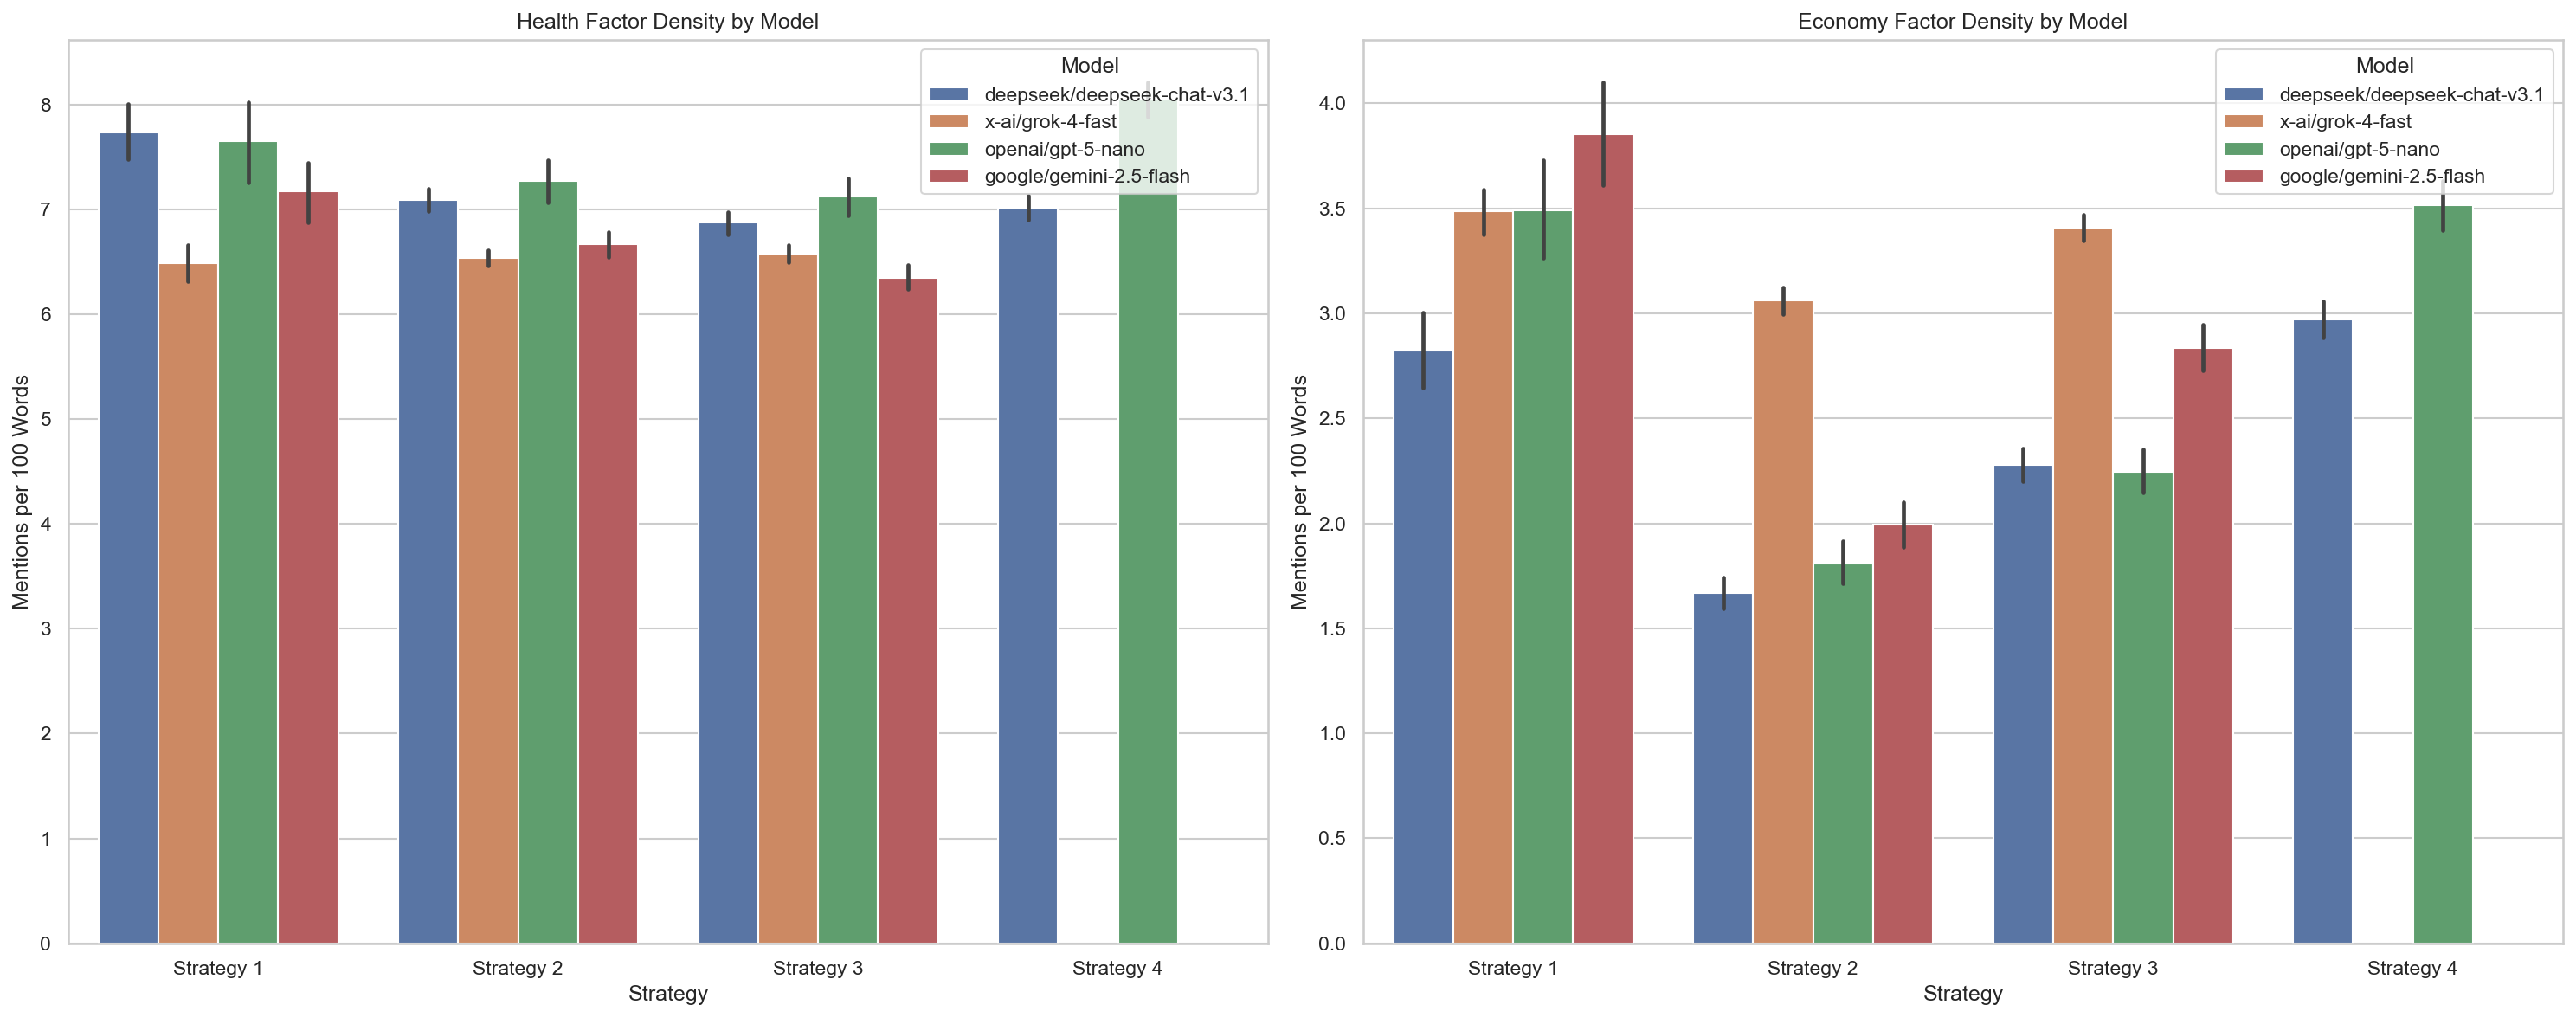

In [41]:
# Set up the figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Health Density Graph
sns.barplot(data=full_df, x='strategy', y='health_density', hue='model', ax=axes[0], errorbar=('ci', 95))
axes[0].set_title('Health Factor Density by Model')
axes[0].set_ylabel('Mentions per 100 Words')
axes[0].set_xlabel('Strategy')
axes[0].legend(title='Model', loc='upper right')

# 2. Economy Density Graph
sns.barplot(data=full_df, x='strategy', y='economy_density', hue='model', ax=axes[1], errorbar=('ci', 95))
axes[1].set_title('Economy Factor Density by Model')
axes[1].set_ylabel('Mentions per 100 Words')
axes[1].set_xlabel('Strategy')
axes[1].legend(title='Model', loc='upper right')

plt.tight_layout()
plt.show()

### 3.3 Context-Specific Analysis

This section analyzes how much each strategy's specific context is referenced in the reasoning.
*   **Strategy 2 (Hospital Capacity)**: Mentions of beds, ICU, capacity, resources.
*   **Strategy 3 (Economic Impact)**: Mentions of economy, jobs, financial impact.
*   **Strategy 4 (User Preferences)**: Mentions of preferences, choice, autonomy.

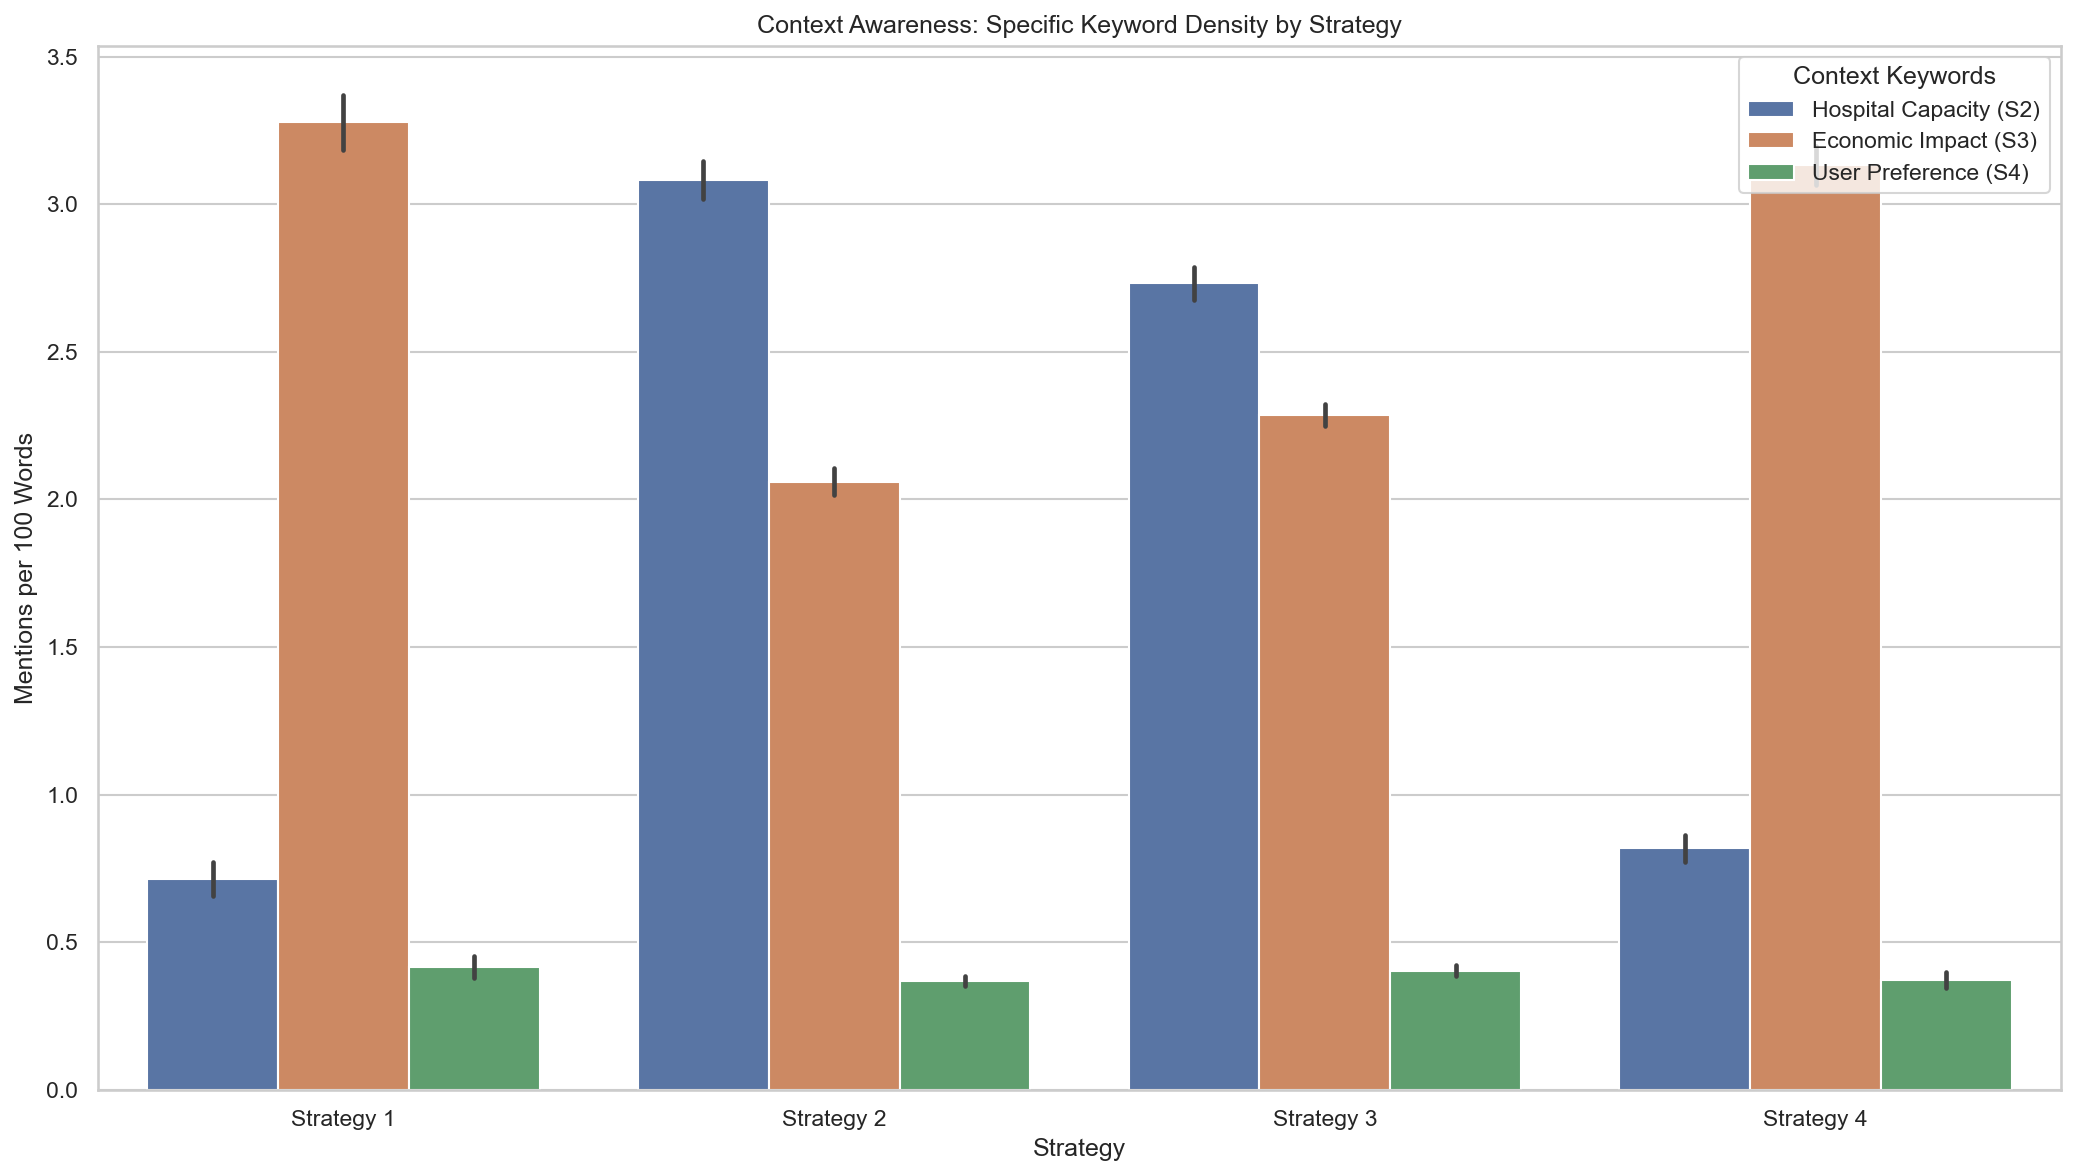

In [42]:
# Define context-specific keywords
s2_keywords = ["capacity", "bed", "icu", "strain", "resource", "overcrowd", "full", "shortage", "limit", "ventilator"]
s3_keywords = ["economy", "economic", "financial", "job", "unemployment", "budget", "gdp", "recession", "livelihood", "business"]
s4_keywords = ["preference", "prefer", "choice", "want", "wish", "personal", "autonomy", "user", "value"]

# Calculate mentions using the previously defined count_keywords function
full_df['s2_mentions'] = full_df['reasoning'].apply(lambda x: count_keywords(x, s2_keywords))
full_df['s3_mentions'] = full_df['reasoning'].apply(lambda x: count_keywords(x, s3_keywords))
full_df['s4_mentions'] = full_df['reasoning'].apply(lambda x: count_keywords(x, s4_keywords))

# Normalize by length (mentions per 100 words)
full_df['s2_density'] = (full_df['s2_mentions'] / full_df['reasoning_length']) * 100
full_df['s3_density'] = (full_df['s3_mentions'] / full_df['reasoning_length']) * 100
full_df['s4_density'] = (full_df['s4_mentions'] / full_df['reasoning_length']) * 100

# Melt for plotting
melted_context = full_df.melt(id_vars=['strategy'], 
                              value_vars=['s2_density', 's3_density', 's4_density'], 
                              var_name='Context_Type', value_name='Density')

# Map names for clearer legend
context_labels = {
    's2_density': 'Hospital Capacity (S2)',
    's3_density': 'Economic Impact (S3)',
    's4_density': 'User Preference (S4)'
}
melted_context['Context_Type'] = melted_context['Context_Type'].map(context_labels)

plt.figure(figsize=(14, 8))
sns.barplot(data=melted_context, x='strategy', y='Density', hue='Context_Type', errorbar=('ci', 95))
plt.title('Context Awareness: Specific Keyword Density by Strategy')
plt.ylabel('Mentions per 100 Words')
plt.xlabel('Strategy')
plt.legend(title='Context Keywords', loc='upper right')
plt.tight_layout()
plt.show()

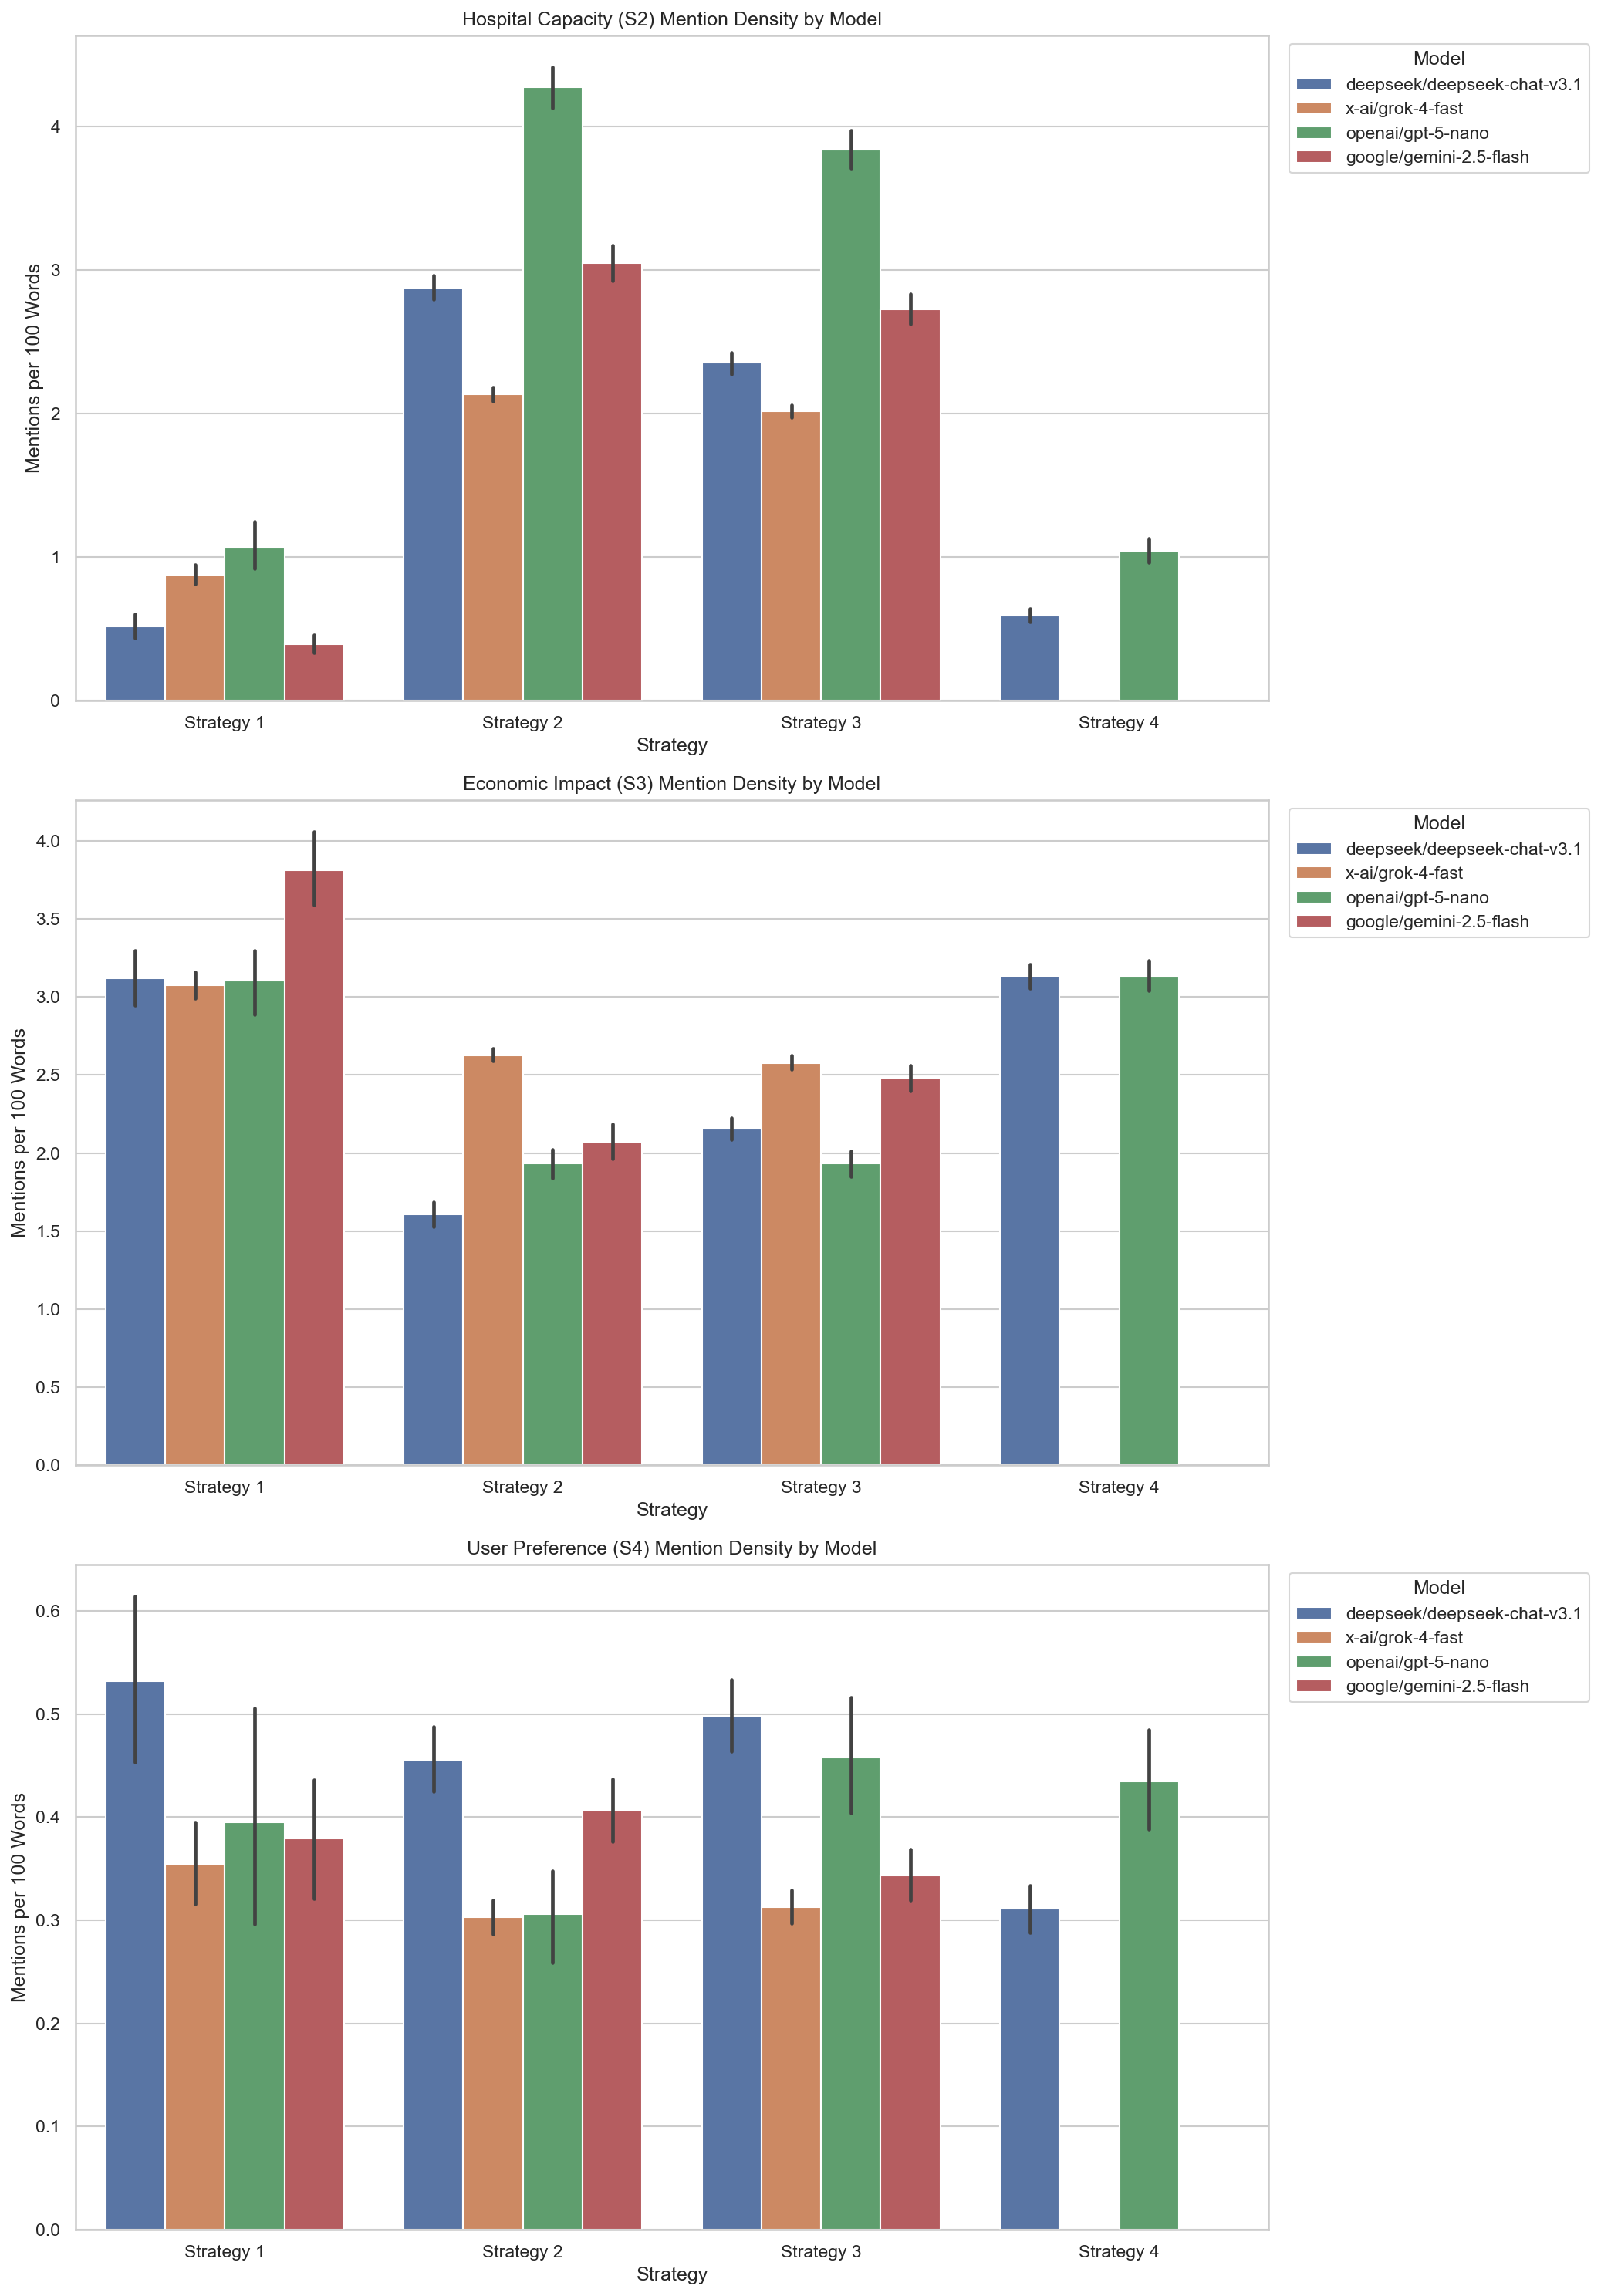

In [43]:
# Set up the figure with 3 rows
fig, axes = plt.subplots(3, 1, figsize=(14, 20))

# Define the contexts to plot
context_vars = [
    ('s2_density', 'Hospital Capacity (S2)'),
    ('s3_density', 'Economic Impact (S3)'),
    ('s4_density', 'User Preference (S4)')
]

for i, (col, title) in enumerate(context_vars):
    sns.barplot(data=full_df, x='strategy', y=col, hue='model', ax=axes[i], errorbar=('ci', 95))
    axes[i].set_title(f'{title} Mention Density by Model')
    axes[i].set_ylabel('Mentions per 100 Words')
    axes[i].set_xlabel('Strategy')
    # Move legend outside to keep graph clean
    axes[i].legend(title='Model', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 3.4 Struggle & Uncertainty Analysis

**Uncertainty Markers**: "difficult choice", "hard to decide", "on the other hand", "balance", "trade-off", "nuanced", "complex"

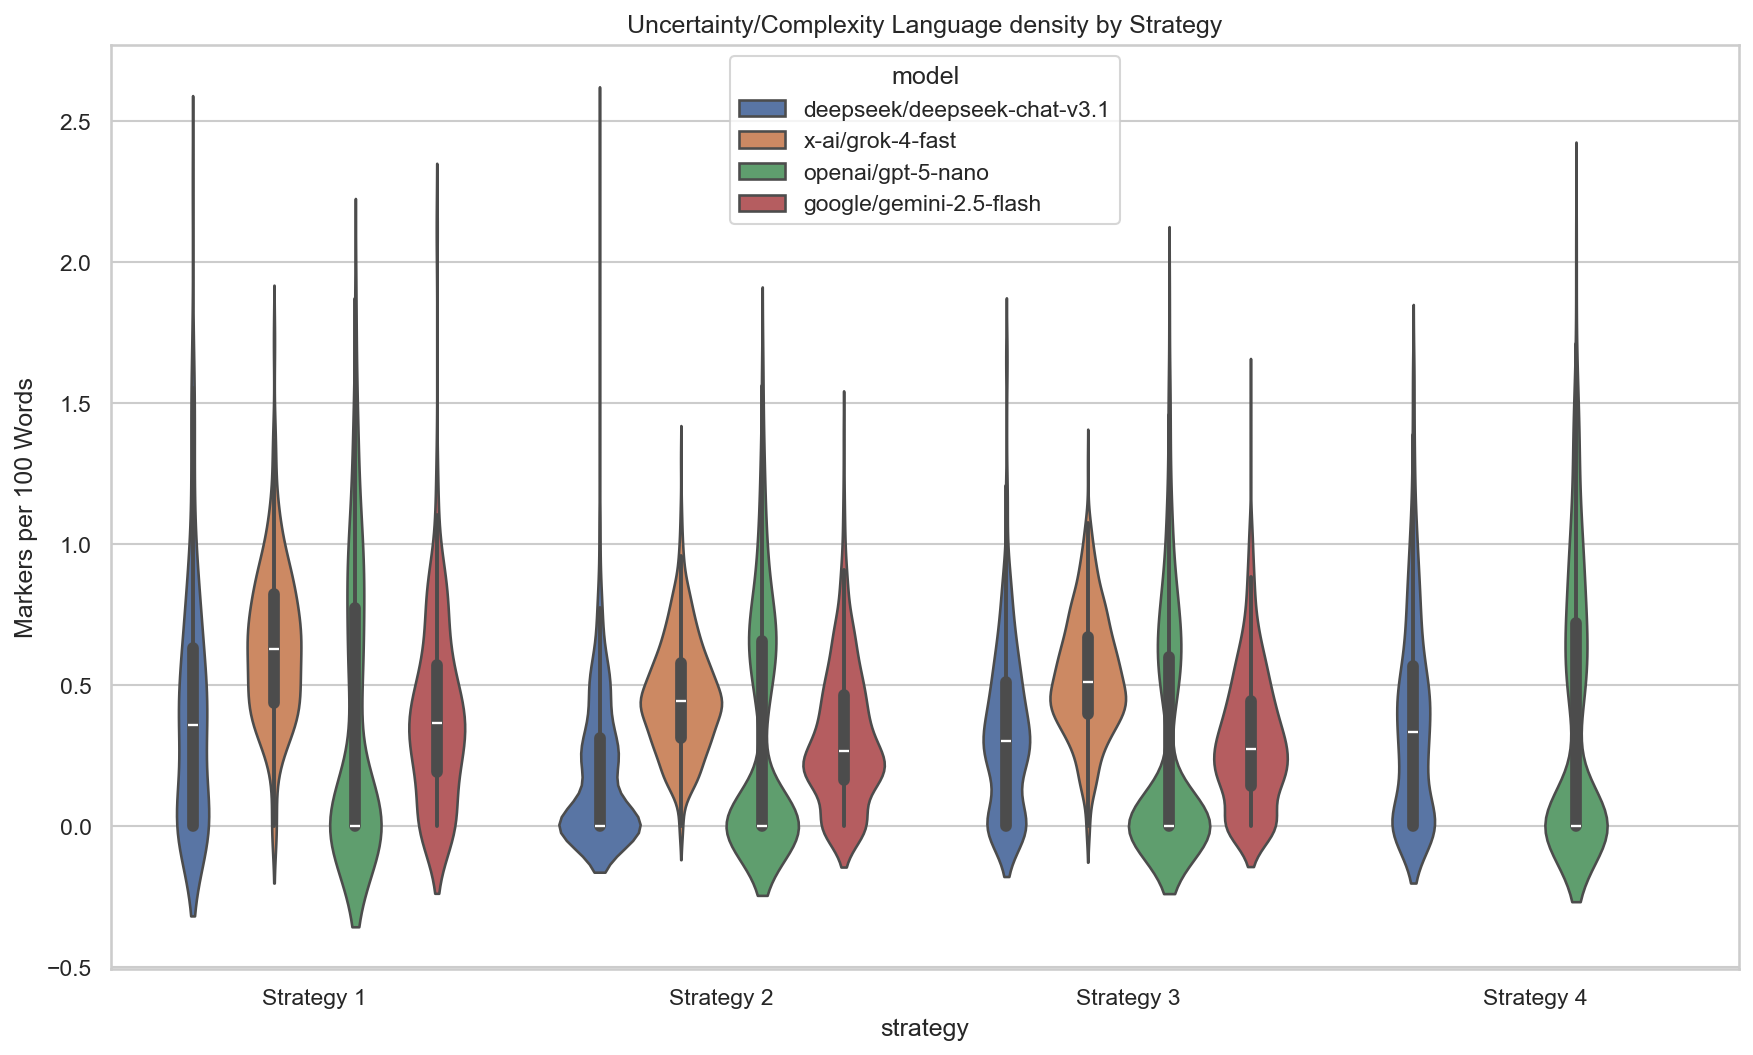

In [44]:
uncertainty_markers = ["difficult", "hard", "challenge", "complex", "nuanced", "balance", "trade-off", "dilemma", "conflict", "tough"]

full_df['uncertainty_score'] = full_df['reasoning'].apply(lambda x: count_keywords(x, uncertainty_markers))
full_df['uncertainty_density'] = (full_df['uncertainty_score'] / full_df['reasoning_length']) * 100

plt.figure(figsize=(14, 8))
sns.violinplot(data=full_df, x='strategy', y='uncertainty_density', hue='model', split=False)
plt.title('Uncertainty/Complexity Language density by Strategy')
plt.ylabel('Markers per 100 Words')
plt.show()

### 3.5 Lexical Diversity

Using Type-Token Ratio (TTR) to see if the vocabulary is repetitive or diverse.

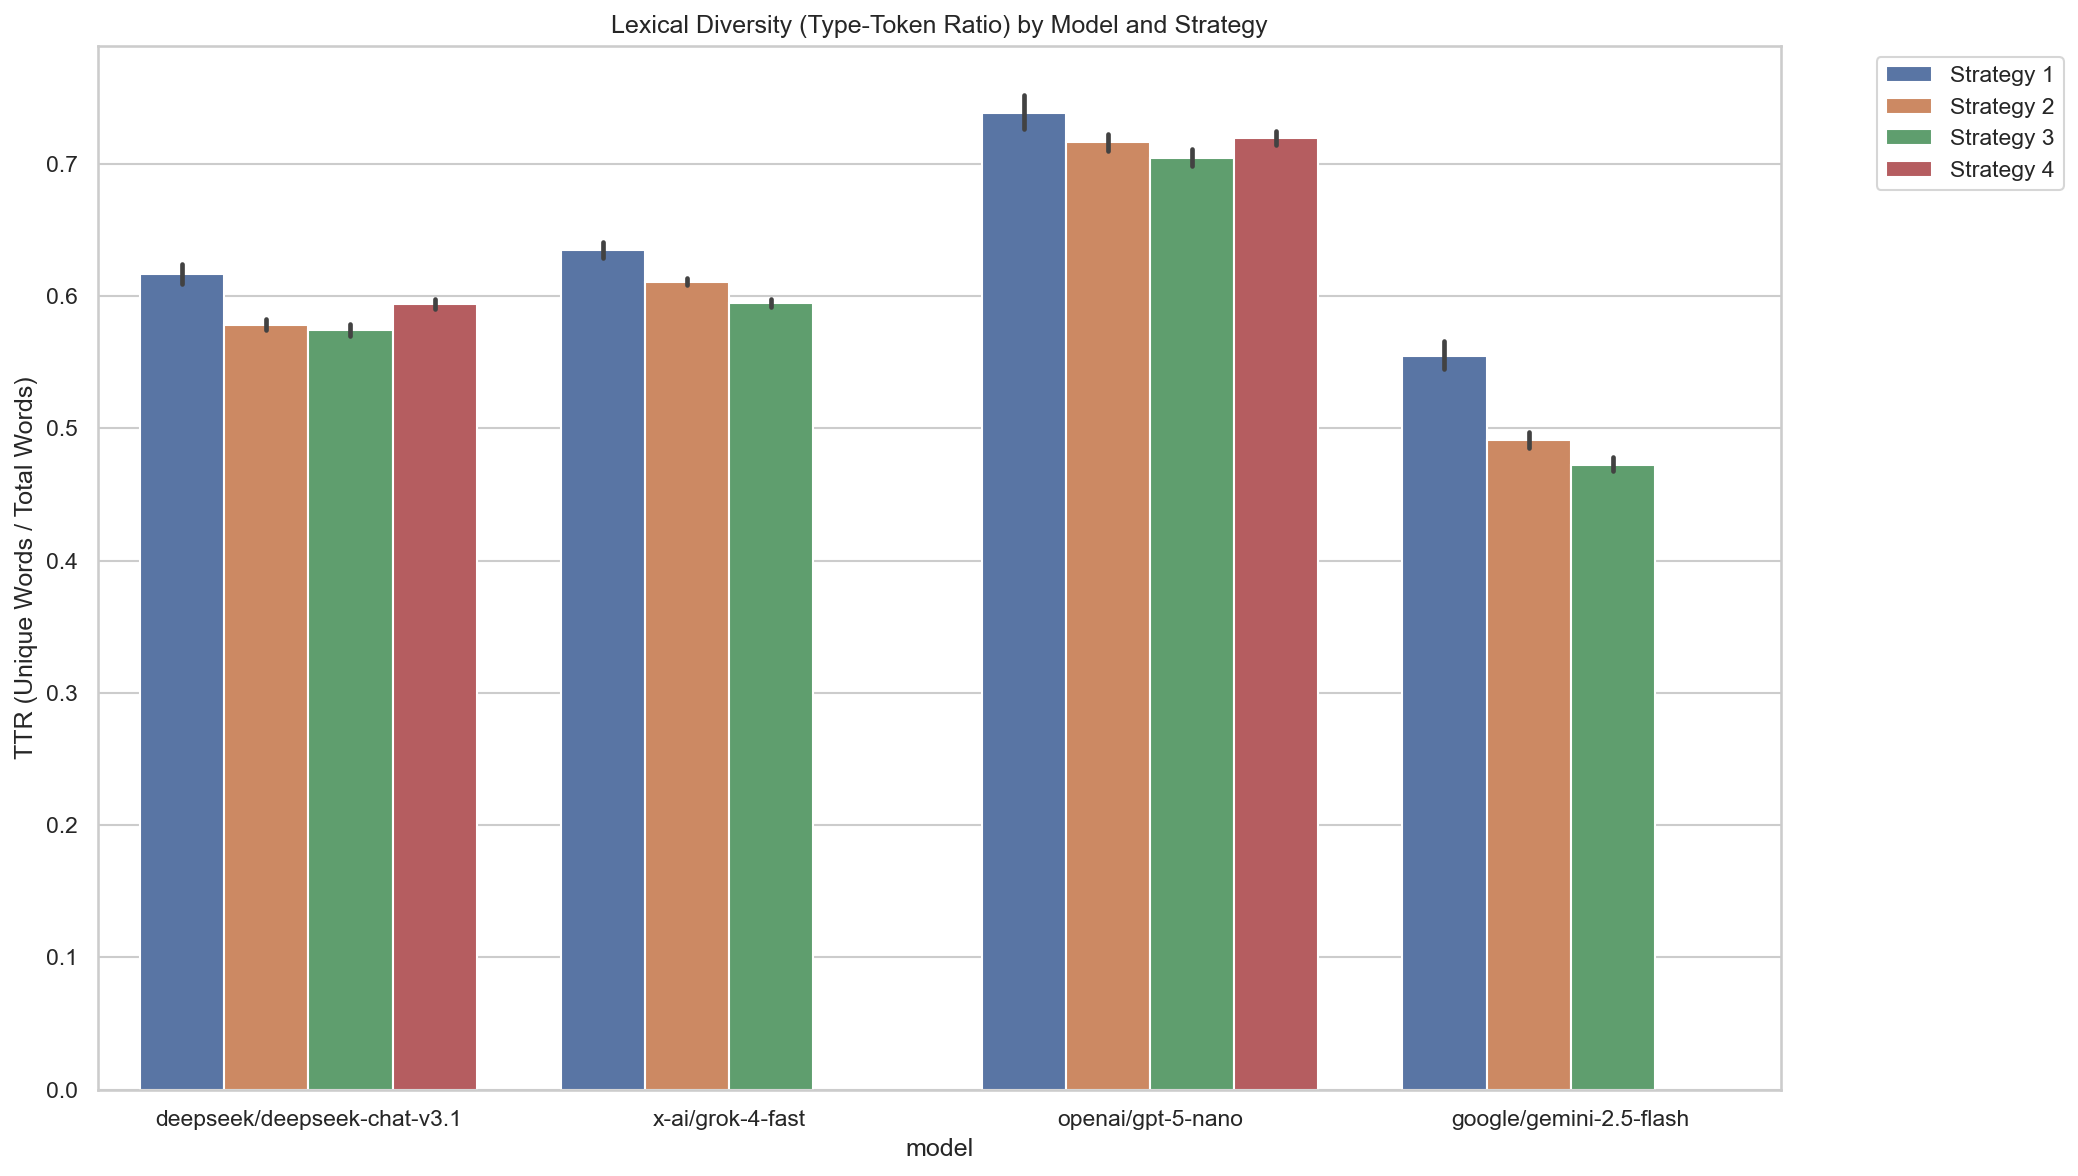

In [45]:
def calculate_ttr(text):
    if not text:
        return 0
    tokens = text.lower().split()
    if len(tokens) == 0:
        return 0
    types = set(tokens)
    return len(types) / len(tokens)

full_df['ttr'] = full_df['reasoning'].apply(calculate_ttr)

plt.figure(figsize=(14, 8))
sns.barplot(data=full_df, x='model', y='ttr', hue='strategy')
plt.title('Lexical Diversity (Type-Token Ratio) by Model and Strategy')
plt.ylabel('TTR (Unique Words / Total Words)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()